# Chapter 16: Downloading Data 

En este capitulo, se descargaran datasets y se creararan visualizaciones de trabajo de los datos. 



## Summary

Los datos de internet se guardan sobre todo en dos formatos: **CSV** (valores separados por comas, que se procesa con el módulo `csv`) y **JSON / GeoJSON** (que se procesa con el módulo `json`).
Con un archivo CSV de clima se lee la fila de **headers**, se identifica en qué posición está cada dato y se extraen fechas y temperaturas a listas.
Con `datetime.strptime()` se convierten strings de fecha en objetos de fecha, y con Matplotlib se grafican una o varias series de datos (`plot()`, `fill_between()`).
Los datos reales pueden tener valores faltantes: un bloque `try-except-else` evita que el programa se caiga.
Con datos GeoJSON de terremotos se recorre un diccionario anidado para extraer magnitud, longitud, latitud y título, y se dibujan en un mapa con `px.scatter_geo()` de Plotly.

## Cheat Sheet

### Leer un archivo CSV

| Quiero... | Sintaxis | Ejemplo | Resultado / nota |
|---|---|---|---|
| Apuntar a un archivo | `Path('ruta')` | `Path('weather_data/sitka_weather_07-2021_simple.csv')` | objeto `Path` (`from pathlib import Path`) |
| Leer el archivo como texto | `path.read_text()` | `path.read_text(encoding='utf-8')` | un solo string con todo el contenido |
| Separar en líneas | `.splitlines()` | `path.read_text().splitlines()` | lista con una línea por elemento |
| Crear un lector de CSV | `csv.reader(lines)` | `reader = csv.reader(lines)` | objeto `reader` (`import csv`) |
| Obtener la siguiente línea | `next(reader)` | `header_row = next(reader)` | la primera llamada devuelve los **headers**; el `reader` sigue desde donde quedó |
| Ver índice y valor | `enumerate(lista)` | `for index, column_header in enumerate(header_row):` | `0 STATION`, `1 NAME`, ... |
| Convertir texto en número | `int(...)` | `high = int(row[4])` | los datos del CSV llegan como strings |
| Recorrer las filas | `for row in reader:` | `for row in reader:` | empieza en la fila siguiente a los headers |

### Fechas con `datetime`

| Quiero... | Sintaxis | Ejemplo | Resultado |
|---|---|---|---|
| Importar | `from datetime import datetime` | | |
| Convertir un string en fecha | `datetime.strptime(texto, formato)` | `datetime.strptime('2021-07-01', '%Y-%m-%d')` | `2021-07-01 00:00:00` |

| Código | Significado |
|---|---|
| `%Y` | año de 4 dígitos (2019) |
| `%y` | año de 2 dígitos (19) |
| `%m` | mes como número (01 a 12) |
| `%B` | nombre del mes (January) |
| `%d` | día del mes (01 a 31) |
| `%A` | nombre del día (Monday) |
| `%H` | hora en formato 24 h (00 a 23) |
| `%I` | hora en formato 12 h (01 a 12) |
| `%p` | AM o PM |
| `%M` | minutos (00 a 59) |
| `%S` | segundos (00 a 61) |

### Gráficos con Matplotlib

| Quiero... | Sintaxis | Ejemplo | Nota |
|---|---|---|---|
| Importar | `import matplotlib.pyplot as plt` | | |
| Aplicar un estilo | `plt.style.use('estilo')` | `plt.style.use('seaborn')` | |
| Crear figura y ejes | `fig, ax = plt.subplots()` | | |
| Graficar una serie | `ax.plot(x, y, color=...)` | `ax.plot(dates, highs, color='red')` | si solo se da `y`, el eje x son los índices |
| Transparencia | `alpha=` | `ax.plot(dates, highs, color='red', alpha=0.5)` | 0 = transparente, 1 = opaco (por defecto) |
| Sombrear entre dos series | `ax.fill_between(x, y1, y2, facecolor=..., alpha=...)` | `ax.fill_between(dates, highs, lows, facecolor='blue', alpha=0.1)` | `facecolor` es el color del área |
| Título | `ax.set_title(texto, fontsize=)` | `ax.set_title("Daily High Temperatures, 2021", fontsize=24)` | `\n` permite un título de dos líneas |
| Etiqueta eje x / y | `ax.set_xlabel()` / `ax.set_ylabel()` | `ax.set_ylabel("Temperature (F)", fontsize=16)` | |
| Tamaño de los números de los ejes | `ax.tick_params(labelsize=)` | `ax.tick_params(labelsize=16)` | |
| Fechas en diagonal | `fig.autofmt_xdate()` | | evita que las fechas se encimen |
| Mostrar | `plt.show()` | | |

### Manejo de datos faltantes

| Quiero... | Sintaxis | Nota |
|---|---|---|
| Intentar extraer y capturar el error | `try:` ... `except ValueError:` ... `else:` | el `else` solo corre si no hubo error |
| Opciones para datos faltantes | `try-except-else` · `continue` · `remove()` · `del` | cualquiera sirve si el resultado es correcto y significativo |

Error típico: `ValueError: invalid literal for int() with base 10: ''` → `int('')`, un dato vacío que no se puede convertir en número.

### JSON / GeoJSON

| Quiero... | Sintaxis | Ejemplo | Nota |
|---|---|---|---|
| Convertir texto JSON en objeto Python | `json.loads(texto)` | `all_eq_data = json.loads(contents)` | el archivo completo pasa a ser un diccionario |
| Convertir objeto Python en texto JSON | `json.dumps(obj, indent=4)` | `json.dumps(all_eq_data, indent=4)` | `indent` define cuánto indentar los niveles |
| Escribir un archivo | `path.write_text(texto)` | `path.write_text(readable_contents)` | |
| Lista de terremotos | `data['features']` | `all_eq_dicts = all_eq_data['features']` | cada elemento es un diccionario |
| Magnitud | `eq['properties']['mag']` | | |
| Título | `eq['properties']['title']` | | resumen de magnitud y lugar |
| Longitud | `eq['geometry']['coordinates'][0]` | | GeoJSON usa **(longitud, latitud)** |
| Latitud | `eq['geometry']['coordinates'][1]` | | |

### Mapas con Plotly (`import plotly.express as px`)

| Argumento de `px.scatter_geo()` | Para qué sirve | Ejemplo |
|---|---|---|
| `lat=`, `lon=` | listas de latitudes y longitudes (lo mínimo) | `lat=lats, lon=lons` |
| `title=` | título del mapa | `title='Global Earthquakes'` |
| `size=` | tamaño de cada punto según una lista | `size=mags` |
| `color=` | valores que determinan el color | `color=mags` |
| `color_continuous_scale=` | escala de colores | `color_continuous_scale='Viridis'` |
| `labels=` | cambia el nombre de una etiqueta (diccionario) | `labels={'color': 'Magnitude'}` |
| `projection=` | proyección del mapa base | `projection='natural earth'` |
| `hover_name=` | texto al pasar el cursor | `hover_name=eq_titles` |

| Otras funciones | Para qué sirve |
|---|---|
| `fig.show()` | muestra el mapa |
| `px.colors.named_colorscales()` | lista las escalas de color disponibles |

Con varios argumentos en líneas distintas es común dejar una coma al final de la última.

## The CSV File Format

### Parsing the CSV File Headers

El modulo de Python `csv` es la libreria estandar que analiza las lineas de un archivo CSV, y permite extraer los valores que nos interesan. 

Empecemos con analizar la primera linea del archivo, que contiene una serie de `headers` de la data. Estos headers dicen qué clase de información contienen los datos:  


In [1]:
from pathlib import Path 

import csv 

path = Path('weather_data/sitka_weather_07-2021_simple.csv')
lines = path.read_text(encoding = 'utf-8').splitlines()

reader = csv.reader(lines)
header_row = next(reader)

print(header_row)

['STATION', 'NAME', 'DATE', 'TAVG', 'TMAX', 'TMIN']


- Primero se importa el modulo `Path` y `csv`.
- Luego, se construye el objeto `Path` que mira dentro de la carpeta `weather_data`, y apunta a los datos especificos de weather con los que se quiere trabajar.
- Se lee el archivo y se encadena el metodo `splitlines()` para tener una lista de todas las lineas del archivo, las cuales se asignan a `lines`. 
- Luego, se construye el objeto `reader`. Este es un objeto que se puede utilizar para analizar cada línea del archivo. Para hacer un `reader object`, llama a la función `csv.reader()` y pasale la lista de lineas del archivo CSV. 
- Cuando se asigna un **`reader` object**, la función `next()` retorna la siguiente linea del archivo, empezando por el inicio de este. 
- Aca se llama a `next()` solo una vez, para obtener la primera linea del archivo, que contiene los ****`headers`**** de las filas. 
- Se le asigna a los datos retornados a la variable `header_row`. 


### Comparison: Parsing the CSV File Headers

| Variable | Qué es | Cómo se obtiene | Ejemplo |
|---|---|---|---|
| `path` | el objeto que apunta al archivo | `Path('weather_data/...')` | `Path('weather_data/sitka_weather_07-2021_simple.csv')` |
| `lines` | lista de strings, una por línea | `path.read_text().splitlines()` | `['"STATION","NAME",...', ...]` |
| `reader` | objeto que analiza cada línea | `csv.reader(lines)` | |
| `header_row` | lista con los nombres de las columnas | `next(reader)` | `['STATION', 'NAME', 'DATE', 'TAVG', 'TMAX', 'TMIN']` |

| Índice | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| Header | `STATION` | `NAME` | `DATE` | `TAVG` | `TMAX` | `TMIN` |
| Qué contiene | código de la estación | nombre de la estación | fecha | temperatura promedio | temperatura máxima | temperatura mínima |

| | `print(header_row)` | `enumerate(header_row)` |
|---|---|---|
| Muestra | la lista completa | cada header **con su posición** |
| Útil para | ver los nombres | saber qué índice usar (`row[4]` para `TMAX`) |

## Printing the Headers and their positions

Para entender de manera más facil el header de los datos, imprimamos cada header y su posicion en la listaa

In [2]:
reader = csv.reader(lines)

header_row = next(reader)

for index, column_header in enumerate(header_row):
    print(index, column_header)

0 STATION
1 NAME
2 DATE
3 TAVG
4 TMAX
5 TMIN


La función `enumerate()` retorna tanto el indice de cada item y el valor de cada item, mientras se recorre la lista. 

## Extracting and Reading Data

Ahora que se sabe que columna de los datos necesitamos, hay que leer alguno de esos datos. 

> Primero, se leera la temperatura alta de cada dia

In [3]:
reader = csv.reader(lines)
header_row = next(reader)

# Extract High temperatures
highs = []
for row in reader:
    high = int(row[4])
    highs.append(high)

print(highs)

[61, 60, 66, 60, 65, 59, 58, 58, 57, 60, 60, 60, 57, 58, 60, 61, 63, 63, 70, 64, 59, 63, 61, 58, 59, 64, 62, 70, 70, 73, 66]


## Plotting Data in a Temperature Chart

Para visualizar la data que se tiene, primero se creara un grafico de las temperaturas máximas diarias.

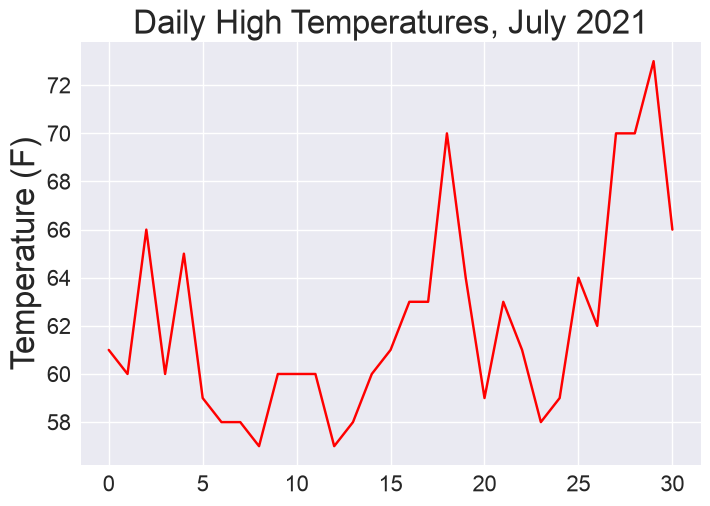

In [ ]:
from pathlib import Path
import csv

import matplotlib.pyplot as plt

path  = Path('weather_data/sitka_weather_07-2021_simple.csv')
lines = path.read_text(encoding='utf-8').splitlines()

# Plot the high temperatures: 
plt.style.use('seaborn-v0_8')
fig, ax = plt.subplots()
ax.plot(highs, color='red')

# Format Plot
ax.set_title("Daily High Temperatures, July 2021", fontsize = 24)
ax.set_xlabel('', fontsize = 16)
ax.set_ylabel("Temperature (F)", fontsize = 24)
ax.tick_params(labelsize = 16)

plt.show()

## Comparison: Chapter 16

| | Sitka | Death Valley |
|---|---|---|
| Archivo | `sitka_weather_2021_simple.csv` | `death_valley_2021_simple.csv` |
| Headers | `STATION, NAME, DATE, TAVG, TMAX, TMIN` | `STATION, NAME, DATE, TMAX, TMIN, TOBS` |
| Índice de `DATE` | 2 | 2 |
| Índice de `TMAX` | **4** | **3** |
| Índice de `TMIN` | **5** | **4** |

Cada archivo tiene sus headers en posiciones distintas: primero hay que imprimirlos con `enumerate()` y recién después elegir los índices.

| | CSV | JSON / GeoJSON |
|---|---|---|
| Módulo | `csv` | `json` |
| Estructura | filas de valores separados por comas | diccionarios y listas anidados |
| Cómo se lee | `csv.reader(lines)` + `next()` + `for row in reader` | `json.loads(contents)` |
| Cómo se accede a un dato | `row[4]` (por posición) | `eq_dict['properties']['mag']` (por llaves) |
| Los datos llegan como | strings (`int(...)` para convertir) | ya con su tipo (números, listas, diccionarios) |

| | `json.loads()` | `json.dumps()` |
|---|---|---|
| Dirección | texto → objeto Python | objeto Python → texto |
| Argumento extra | — | `indent=4` para hacerlo legible |

| | `ax.plot(dates, highs)` | `ax.fill_between(dates, highs, lows)` |
|---|---|---|
| Dibuja | una línea | el área entre dos series |
| Series de y | una | dos |
| Color | `color=` | `facecolor=` |

| | `try-except-else` | `continue` | `remove()` / `del` |
|---|---|---|---|
| Qué hace con el dato faltante | lo captura (`ValueError`) y lo avisa | salta a la siguiente vuelta | lo elimina después de extraerlo |
| Cuándo usarlo | datos que pueden fallar al convertirse | se quiere ignorar esa fila sin avisar | se quiere limpiar una lista ya armada |

| | Matplotlib | Plotly Express |
|---|---|---|
| Se usó para | gráficos de líneas (temperaturas) | mapas de dispersión geográfica (terremotos) |
| Función principal | `ax.plot()` | `px.scatter_geo()` |
| Importación | `import matplotlib.pyplot as plt` | `import plotly.express as px` |

| Para representar... en el mapa | Argumento |
|---|---|
| tamaño según la magnitud | `size=mags` |
| color según la magnitud | `color=mags` |
| texto al pasar el cursor | `hover_name=eq_titles` |